# MARA Anomaly Detection with Isolation Forest

This notebook uses the Isolation Forest algorithm to detect anomalies in the MARA (Material Master) dataset from our CDC pipeline.

## 2. Import Libraries

In [1]:
import pandas as pd
import numpy as np
from sklearn.ensemble import IsolationForest
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Set style for better visualizations
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

## 3. Load Dataset

In [2]:
# Load the MARA dataset
df = pd.read_csv('mara.csv')

print(f"Dataset shape: {df.shape}")
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

Dataset shape: (30, 20)
Number of rows: 30
Number of columns: 20


## 4. Explore Data

In [3]:
# Display first few rows
print("First 5 rows:")
print(df.head())
print("\n" + "="*80 + "\n")

First 5 rows:
   mandt       matnr     ersda     ernam     laeda     aenam mtart  matkl  \
0    800    IAD-5006  20210326  SCHULZET         0       NaN  HIBE  300.0   
1    800    IAD-5007  20210326  SCHULZET         0       NaN  HIBE  300.0   
2    800   IAD-S3000  20211215  DEVENTER  19991201  SCHULZET  DIEN  300.0   
3    800  IAD-SC3000  20211130  SCHULZET  20000818  SCHULZET  DIEN    7.0   
4    800     IBG-100  20220809     GRACH         0       NaN  FERT    1.0   

  meins  brgew  ntgew gewei  volum voleh  laeng  breit  hoehe  meabm  bismt  \
0    ST    0.0    0.0    KG   0.00   NaN    0.0    0.0    0.0    NaN    NaN   
1    ST    0.0    0.0    KG   0.00   NaN    0.0    0.0    0.0    NaN    NaN   
2    LE    0.0    0.0   NaN   0.00   NaN    0.0    0.0    0.0    NaN    NaN   
3    LE    0.0    0.0   NaN   0.00   NaN    0.0    0.0    0.0    NaN    NaN   
4    ST  280.0  250.0    KG   0.75    M3    0.0    0.0    0.0    NaN    NaN   

   lvorm  
0    NaN  
1    NaN  
2    NaN  
3   

In [4]:
# Data types and info
print("Data types and info:")
print(df.info())
print("\n" + "="*80 + "\n")

Data types and info:
<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 20 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   mandt   30 non-null     int64  
 1   matnr   30 non-null     str    
 2   ersda   30 non-null     int64  
 3   ernam   30 non-null     str    
 4   laeda   30 non-null     int64  
 5   aenam   15 non-null     str    
 6   mtart   30 non-null     str    
 7   matkl   24 non-null     float64
 8   meins   30 non-null     str    
 9   brgew   30 non-null     float64
 10  ntgew   30 non-null     float64
 11  gewei   15 non-null     str    
 12  volum   30 non-null     float64
 13  voleh   3 non-null      str    
 14  laeng   30 non-null     float64
 15  breit   30 non-null     float64
 16  hoehe   30 non-null     float64
 17  meabm   0 non-null      float64
 18  bismt   0 non-null      float64
 19  lvorm   0 non-null      float64
dtypes: float64(10), int64(3), str(7)
memory usage: 4.8 KB
None




In [5]:
# Summary statistics for numeric columns
print("Summary statistics:")
print(df.describe())

Summary statistics:
       mandt         ersda         laeda       matkl       brgew       ntgew  \
count   30.0  3.000000e+01  3.000000e+01   24.000000   30.000000   30.000000   
mean   800.0  2.022257e+07  1.001558e+07   58.291667   10.494000    9.153667   
std      0.0  1.498406e+04  1.018688e+07  108.998396   50.960363   45.540233   
min    800.0  2.021022e+07  0.000000e+00    1.000000    0.000000    0.000000   
25%    800.0  2.021024e+07  0.000000e+00    1.000000    0.000000    0.000000   
50%    800.0  2.022081e+07  9.980402e+06    8.000000    0.000000    0.000000   
75%    800.0  2.022081e+07  2.001589e+07   10.000000    1.950000    0.602500   
max    800.0  2.025041e+07  2.012050e+07  300.000000  280.000000  250.000000   

           volum  laeng  breit  hoehe  meabm  bismt  lvorm  
count  30.000000   30.0   30.0   30.0    0.0    0.0    0.0  
mean    0.027400    0.0    0.0    0.0    NaN    NaN    NaN  
std     0.136927    0.0    0.0    0.0    NaN    NaN    NaN  
min     0.00000

In [6]:
# Check for missing values
print("Missing values:")
print(df.isnull().sum())
print(f"\nTotal missing values: {df.isnull().sum().sum()}")

Missing values:
mandt     0
matnr     0
ersda     0
ernam     0
laeda     0
aenam    15
mtart     0
matkl     6
meins     0
brgew     0
ntgew     0
gewei    15
volum     0
voleh    27
laeng     0
breit     0
hoehe     0
meabm    30
bismt    30
lvorm    30
dtype: int64

Total missing values: 153


## 5. Prepare Data for Training

Select numeric columns and handle missing values for Isolation Forest.

In [7]:
# Select numeric columns (weight, volume, dimensions)
numeric_cols = ['brgew', 'ntgew', 'volum', 'laeng', 'breit', 'hoehe']

# Create a copy with only numeric columns
df_numeric = df[numeric_cols].copy()

# Fill missing values with 0 (assuming missing = not applicable)
df_numeric = df_numeric.fillna(0)

print(f"Selected {len(numeric_cols)} numeric features:")
print(numeric_cols)
print(f"\nData shape for training: {df_numeric.shape}")
print(f"\nFeature statistics after handling missing values:")
print(df_numeric.describe())

Selected 6 numeric features:
['brgew', 'ntgew', 'volum', 'laeng', 'breit', 'hoehe']

Data shape for training: (30, 6)

Feature statistics after handling missing values:
            brgew       ntgew      volum  laeng  breit  hoehe
count   30.000000   30.000000  30.000000   30.0   30.0   30.0
mean    10.494000    9.153667   0.027400    0.0    0.0    0.0
std     50.960363   45.540233   0.136927    0.0    0.0    0.0
min      0.000000    0.000000   0.000000    0.0    0.0    0.0
25%      0.000000    0.000000   0.000000    0.0    0.0    0.0
50%      0.000000    0.000000   0.000000    0.0    0.0    0.0
75%      1.950000    0.602500   0.000000    0.0    0.0    0.0
max    280.000000  250.000000   0.750000    0.0    0.0    0.0


## 6. Train Isolation Forest Model

Isolation Forest works by isolating observations by randomly selecting a feature and randomly selecting a split value. Anomalies are easier to isolate and thus have shorter path lengths in the tree.

In [8]:
# Build sklearn Pipeline with preprocessing + model
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Create pipeline with imputer and model
pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value=0)),
    ('isolation_forest', IsolationForest(
        contamination=0.1,      # Expect ~10% anomalies
        random_state=42,        # For reproducibility
        n_estimators=100,       # Number of trees
        max_samples='auto',     # Use all samples
        n_jobs=-1               # Use all CPU cores
    ))
])

# Train the pipeline
print("Training Pipeline (Imputer + Isolation Forest)...")
pipeline.fit(df_numeric)
print("✓ Pipeline trained successfully!")
print(f"  Steps: {list(pipeline.named_steps.keys())}")
print(f"  Model: {type(pipeline.named_steps['isolation_forest']).__name__}")

Training Pipeline (Imputer + Isolation Forest)...
✓ Pipeline trained successfully!
  Steps: ['imputer', 'isolation_forest']
  Model: IsolationForest


## 7. Detect Anomalies

Use the trained model to predict anomalies. The model returns:
- **-1** for anomalies (outliers)
- **1** for normal points (inliers)

In [9]:
# Predict anomalies using the pipeline
predictions = pipeline.predict(df_numeric)

# Get anomaly scores (access the model step directly for score_samples)
anomaly_scores = pipeline.named_steps['isolation_forest'].score_samples(
    pipeline.named_steps['imputer'].transform(df_numeric)
)

# Add predictions and scores to original dataframe
df['anomaly'] = predictions
df['anomaly_score'] = anomaly_scores
df['is_anomaly'] = df['anomaly'] == -1

print(f"Predictions completed!")
print(f"Anomaly labels: -1 (anomaly), 1 (normal)")

Predictions completed!
Anomaly labels: -1 (anomaly), 1 (normal)


## 8. Visualize Anomalies

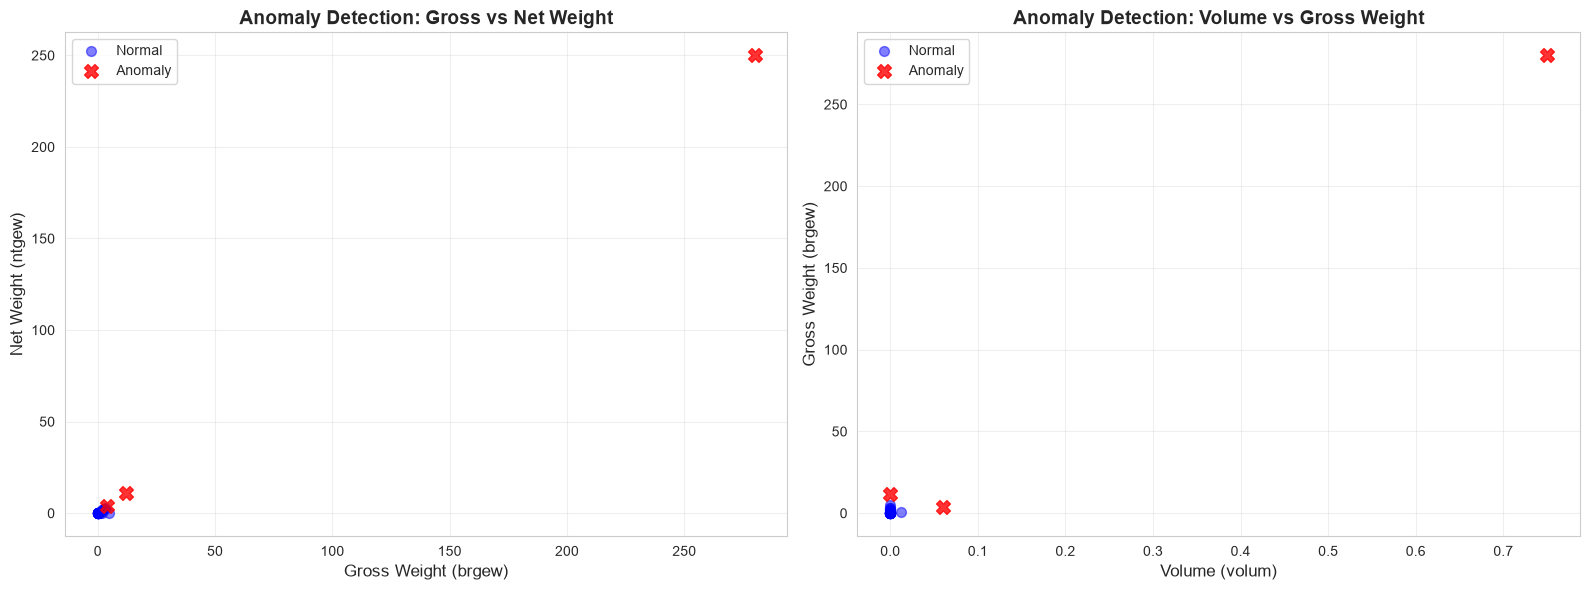

In [10]:
# Scatter plot: Gross Weight vs Net Weight
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Gross vs Net Weight
ax1 = axes[0]
normal = df[df['anomaly'] == 1]
anomalies = df[df['anomaly'] == -1]

ax1.scatter(normal['brgew'], normal['ntgew'], 
           c='blue', alpha=0.5, label='Normal', s=50)
ax1.scatter(anomalies['brgew'], anomalies['ntgew'], 
           c='red', alpha=0.8, label='Anomaly', s=100, marker='X')
ax1.set_xlabel('Gross Weight (brgew)', fontsize=12)
ax1.set_ylabel('Net Weight (ntgew)', fontsize=12)
ax1.set_title('Anomaly Detection: Gross vs Net Weight', fontsize=14, fontweight='bold')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Plot 2: Volume vs Gross Weight
ax2 = axes[1]
ax2.scatter(normal['volum'], normal['brgew'], 
           c='blue', alpha=0.5, label='Normal', s=50)
ax2.scatter(anomalies['volum'], anomalies['brgew'], 
           c='red', alpha=0.8, label='Anomaly', s=100, marker='X')
ax2.set_xlabel('Volume (volum)', fontsize=12)
ax2.set_ylabel('Gross Weight (brgew)', fontsize=12)
ax2.set_title('Anomaly Detection: Volume vs Gross Weight', fontsize=14, fontweight='bold')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

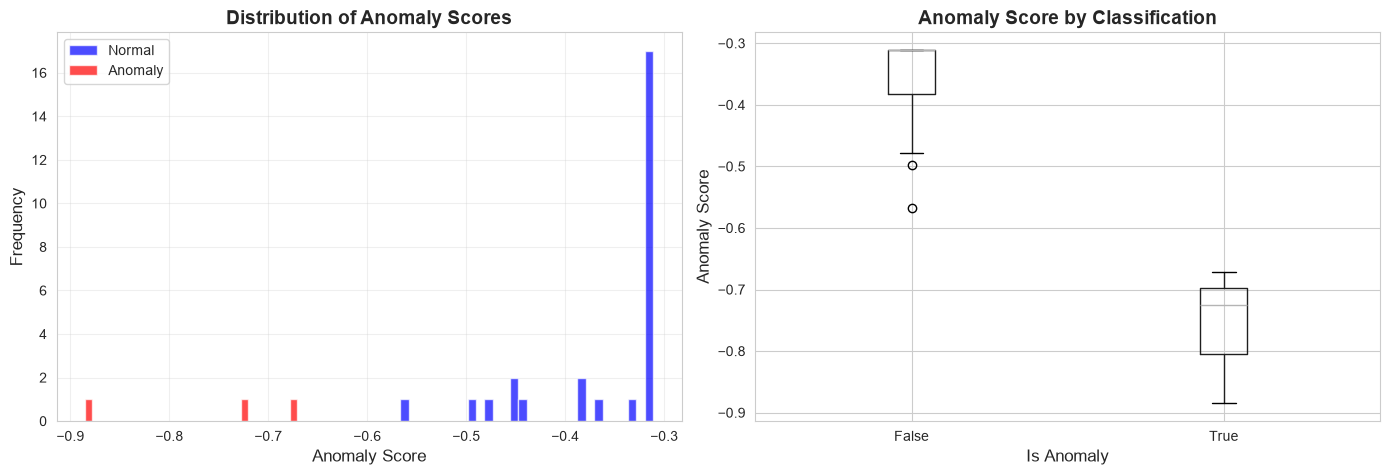

In [11]:
# Anomaly score distribution
plt.figure(figsize=(14, 5))

# Histogram
plt.subplot(1, 2, 1)
plt.hist(df[df['anomaly'] == 1]['anomaly_score'], bins=30, alpha=0.7, label='Normal', color='blue')
plt.hist(df[df['anomaly'] == -1]['anomaly_score'], bins=30, alpha=0.7, label='Anomaly', color='red')
plt.xlabel('Anomaly Score', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.title('Distribution of Anomaly Scores', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)

# Box plot
plt.subplot(1, 2, 2)
df.boxplot(column='anomaly_score', by='is_anomaly', ax=plt.gca())
plt.xlabel('Is Anomaly', fontsize=12)
plt.ylabel('Anomaly Score', fontsize=12)
plt.title('Anomaly Score by Classification', fontsize=14, fontweight='bold')
plt.suptitle('')  # Remove default title

plt.tight_layout()
plt.show()

## 9. Display Anomaly Statistics

In [12]:
# Count anomalies
n_anomalies = (df['anomaly'] == -1).sum()
n_normal = (df['anomaly'] == 1).sum()
total = len(df)
anomaly_percentage = (n_anomalies / total) * 100

print("="*80)
print("ANOMALY DETECTION RESULTS")
print("="*80)
print(f"\n📊 Overall Statistics:")
print(f"  Total records: {total}")
print(f"  Normal points: {n_normal} ({(n_normal/total)*100:.1f}%)")
print(f"  Anomalies detected: {n_anomalies} ({anomaly_percentage:.1f}%)")
print(f"\n🎯 Anomaly Score Range:")
print(f"  Min score: {df['anomaly_score'].min():.4f}")
print(f"  Max score: {df['anomaly_score'].max():.4f}")
print(f"  Mean score (normal): {df[df['anomaly']==1]['anomaly_score'].mean():.4f}")
print(f"  Mean score (anomalies): {df[df['anomaly']==-1]['anomaly_score'].mean():.4f}")

ANOMALY DETECTION RESULTS

📊 Overall Statistics:
  Total records: 30
  Normal points: 27 (90.0%)
  Anomalies detected: 3 (10.0%)

🎯 Anomaly Score Range:
  Min score: -0.8850
  Max score: -0.3112
  Mean score (normal): -0.3568
  Mean score (anomalies): -0.7601


In [13]:
# Display anomalous records
print("\n" + "="*80)
print("🔴 ANOMALOUS RECORDS (Top 10 by anomaly score)")
print("="*80)

anomalies_df = df[df['anomaly'] == -1].sort_values('anomaly_score').head(10)
display_cols = ['mandt', 'matnr', 'mtart', 'brgew', 'ntgew', 'volum', 'anomaly_score']
print(anomalies_df[display_cols].to_string(index=False))

print("\n" + "="*80)


🔴 ANOMALOUS RECORDS (Top 10 by anomaly score)
 mandt    matnr mtart  brgew  ntgew  volum  anomaly_score
   800  IBG-100  FERT  280.0  250.0   0.75      -0.884968
   800 1500-300  HALB   12.0   11.0   0.00      -0.724420
   800 1400-750  HAWA    3.8    3.8   0.06      -0.670974



In [14]:
# Feature analysis for anomalies
print("\n📈 Feature Analysis for Anomalies:")
print("\nMean values comparison:")
comparison = pd.DataFrame({
    'Normal': df[df['anomaly'] == 1][numeric_cols].mean(),
    'Anomaly': df[df['anomaly'] == -1][numeric_cols].mean()
})
print(comparison)


📈 Feature Analysis for Anomalies:

Mean values comparison:
         Normal    Anomaly
brgew  0.704444  98.600000
ntgew  0.363333  88.266667
volum  0.000444   0.270000
laeng  0.000000   0.000000
breit  0.000000   0.000000
hoehe  0.000000   0.000000


## Summary

The Isolation Forest model has successfully identified anomalies in the MARA dataset based on physical properties (weight, volume, dimensions). 

**Key Findings:**
- Anomalies are materials with unusual combinations of physical attributes
- Lower anomaly scores indicate more unusual patterns
- These could represent data quality issues, special materials, or data entry errors

**Next Steps:**
1. Review anomalies with domain experts
2. Investigate root causes (data entry vs. legitimate special cases)
3. Create feedback loop to improve model
4. Deploy as batch job in ClickHouse pipeline

## 10. Save Model for Production

Save the trained Isolation Forest model and configuration for deployment in the ML batch service.

In [15]:
import pickle
import json
from datetime import datetime

# Save the trained Pipeline (includes preprocessing + model)
pipeline_filename = 'anomaly_detection_pipeline.pkl'
with open(pipeline_filename, 'wb') as f:
    pickle.dump(pipeline, f)

print(f"✓ Pipeline saved to: {pipeline_filename}")
print(f"  Pipeline steps: {list(pipeline.named_steps.keys())}")
print(f"  Imputer strategy: constant (fill_value=0)")
print(f"  Model: IsolationForest (n_estimators=100, contamination=0.1)")

✓ Pipeline saved to: anomaly_detection_pipeline.pkl
  Pipeline steps: ['imputer', 'isolation_forest']
  Imputer strategy: constant (fill_value=0)
  Model: IsolationForest (n_estimators=100, contamination=0.1)


In [16]:
# Save model configuration and metadata
model_config = {
    'model_version': 'isolation-forest-v1.0',
    'model_type': 'sklearn.Pipeline',
    'trained_at': datetime.now().isoformat(),
    'training_samples': int(len(df)),
    'features': numeric_cols,
    'pipeline_steps': [
        {
            'name': 'imputer',
            'type': 'SimpleImputer',
            'strategy': 'constant',
            'fill_value': 0
        },
        {
            'name': 'isolation_forest',
            'type': 'IsolationForest',
            'contamination': 0.1,
            'n_estimators': 100,
            'max_samples': 'auto',
            'random_state': 42
        }
    ],
    'usage': {
        'input': 'DataFrame with columns: ' + str(numeric_cols),
        'output': 'predictions array (-1=anomaly, 1=normal) and scores'
    },
    'performance': {
        'anomalies_detected': int(n_anomalies),
        'anomaly_percentage': float(anomaly_percentage),
        'min_anomaly_score': float(df['anomaly_score'].min()),
        'max_anomaly_score': float(df['anomaly_score'].max())
    }
}

config_filename = 'model_config.json'
with open(config_filename, 'w') as f:
    json.dump(model_config, f, indent=2)

print(f"✓ Configuration saved to: {config_filename}")
print(f"\nModel Configuration:")
print(json.dumps(model_config, indent=2))

✓ Configuration saved to: model_config.json

Model Configuration:
{
  "model_version": "isolation-forest-v1.0",
  "model_type": "sklearn.Pipeline",
  "trained_at": "2026-08-08T21:02:18.849041",
  "training_samples": 30,
  "features": [
    "brgew",
    "ntgew",
    "volum",
    "laeng",
    "breit",
    "hoehe"
  ],
  "pipeline_steps": [
    {
      "name": "imputer",
      "type": "SimpleImputer",
      "strategy": "constant",
      "fill_value": 0
    },
    {
      "name": "isolation_forest",
      "type": "IsolationForest",
      "contamination": 0.1,
      "n_estimators": 100,
      "max_samples": "auto",
      "random_state": 42
    }
  ],
  "usage": {
    "input": "DataFrame with columns: ['brgew', 'ntgew', 'volum', 'laeng', 'breit', 'hoehe']",
    "output": "predictions array (-1=anomaly, 1=normal) and scores"
  },
  "performance": {
    "anomalies_detected": 3,
    "anomaly_percentage": 10.0,
    "min_anomaly_score": -0.8849684941114709,
    "max_anomaly_score": -0.31123424073

In [17]:
# Test loading the saved pipeline
print("Testing pipeline persistence...")

# Load the pipeline
with open(pipeline_filename, 'rb') as f:
    loaded_pipeline = pickle.load(f)

# Test with sample data (including missing values)
test_data = pd.DataFrame({
    'brgew': [10.5, None, 15.0],
    'ntgew': [9.2, 12.0, None],
    'volum': [0.5, 0.8, 1.0],
    'laeng': [50.0, None, 60.0],
    'breit': [20.0, 25.0, 30.0],
    'hoehe': [30.0, 35.0, None]
})

# Verify it works (pipeline handles missing values automatically)
test_predictions = loaded_pipeline.predict(test_data)
test_scores = loaded_pipeline.named_steps['isolation_forest'].score_samples(
    loaded_pipeline.named_steps['imputer'].transform(test_data)
)

print(f"✓ Pipeline loaded successfully!")
print(f"  Test predictions: {test_predictions}")
print(f"  Test scores: {test_scores}")
print(f"  Missing values handled automatically by imputer")
print(f"\n🎉 Pipeline is ready for deployment!")
print(f"\nUsage in ML service:")
print(f"  1. Load pipeline: pipeline = pickle.load(open('anomaly_detection_pipeline.pkl', 'rb'))")
print(f"  2. Parse JSON to DataFrame: df = pd.DataFrame(json_list)[{numeric_cols}]")
print(f"  3. Predict: predictions = pipeline.predict(df)")

Testing pipeline persistence...
✓ Pipeline loaded successfully!
  Test predictions: [-1 -1 -1]
  Test scores: [-0.76782629 -0.7443337  -0.75523457]
  Missing values handled automatically by imputer

🎉 Pipeline is ready for deployment!

Usage in ML service:
  1. Load pipeline: pipeline = pickle.load(open('anomaly_detection_pipeline.pkl', 'rb'))
  2. Parse JSON to DataFrame: df = pd.DataFrame(json_list)[['brgew', 'ntgew', 'volum', 'laeng', 'breit', 'hoehe']]
  3. Predict: predictions = pipeline.predict(df)


### Benefits of Pipeline Approach

✅ **Single .pkl file** - Everything in one place (preprocessing + model)  
✅ **No separate preprocessing code** - Pipeline handles imputation automatically  
✅ **Consistent transformations** - Training and inference use same code  
✅ **Simpler ML service** - Just load pipeline and call predict()  

**ML Service Code (simplified):**
```python
import pickle
import pandas as pd

# One-time: Load pipeline
pipeline = pickle.load(open('anomaly_detection_pipeline.pkl', 'rb'))

# Per batch:
json_list = query_clickhouse("SELECT after_json FROM cdc_events WHERE ...")
df = pd.DataFrame(json_list)[['brgew', 'ntgew', 'volum', 'laeng', 'breit', 'hoehe']]
predictions = pipeline.predict(df)  # That's it!
```